## Demonstrate parameter estimation of GB signal
- Data: TDC II-0.1 verification dataset with VGBs (download links: [data](https://zenodo.org/records/15469724/files/0_1_VGB_TDIXYZ.h5?download=1), [parameters](https://zenodo.org/records/15532090/files/0_1_VGB_parameters.h5?download=1)).  
- Template: ``TDIFly`` waveform model 
- Methods: ``NESSAI`` nested sampler implemented in ``BILBY`` 

NOTE that this example requires the installation of ``Triangle_GB`` (see the Installation section of the repository README).

In [1]:
import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"

from Triangle.Constants import *
from Triangle.FFTTools import *
from Triangle.Noise import *
from Triangle.Orbit import *
from Triangle.Data import *
from Triangle.TDI import *
from Triangle.GW import *
from Triangle_GB.TDIFly import * 

import matplotlib
# matplotlib.rcParams['text.usetex'] = True
# matplotlib.rcParams['font.family'] = 'serif'
import matplotlib.pyplot as plt

import multiprocessing
if __name__ == "__main__":
    multiprocessing.set_start_method("fork")

PyCBC.libutils: pkg-config call failed, setting NO_PKGCONFIG=1


No phenomxpy.
No pyseobnr.
no cupy 
no cupy 


/Users/leichang/Documents/Score-Based diffusion in TDC data anysis and parameter estimation/research-repository/environments/triangle-gb/.venv/lib/python3.11/site-packages/pycbc/waveform/plugin.py:99: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
DATA_DIR = "/Users/taijidatacenter/workspace/TDCData/0_1_VGB_TDIXYZ.h5"
PARAM_DIR = "/Users/taijidatacenter/workspace/TDCData/0_1_VGB_parameters.h5"
ORBIT_DIR = "../../Triangle-Simulator/OrbitData/MicroSateOrbitEclipticTCB"

## Load TDI data and true parameters

### Time-domain data and parameters 

In [3]:
with h5py.File(DATA_DIR, "r") as h5file: 
    data_dict = read_dict_from_h5(h5file["/"])

with h5py.File(PARAM_DIR, "r") as h5file: 
    inject_parameters = read_dict_from_h5(h5file["/"])

data_dict.keys(), inject_parameters.keys()

(dict_keys(['XYZ', 'time']),
 dict_keys(['A', 'f0', 'fdot0', 'inclination', 'latitude', 'longitude', 'phase0', 'psi']))

In [4]:
dt = data_dict["time"][1] - data_dict["time"][0]

# pad data to start from t=0
data_time_pad = np.arange(start=0., stop=data_dict["time"][0], step=dt)
data_time = np.concatenate((data_time_pad, data_dict["time"]))

Tobs = len(data_time) * dt 

A_data, E_data, _ = AETfromXYZ(data_dict["XYZ"]["X2"], data_dict["XYZ"]["Y2"], data_dict["XYZ"]["Z2"])
data_channels_td = np.zeros((2, len(data_time)))
data_channels_td[0][len(data_time_pad):] = A_data
data_channels_td[1][len(data_time_pad):] = E_data

channel_names = ["A", "E"]

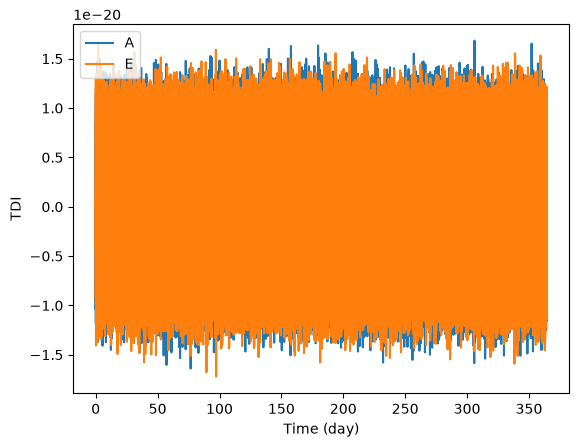

In [5]:
for i in range(len(data_channels_td)):
    plt.plot(data_time/DAY, data_channels_td[i], label=channel_names[i])
plt.xlabel("Time (day)")
plt.ylabel("TDI")
plt.legend(loc="upper left")

### Fourier transform 

In [6]:
data_channels_fd = [] 
for i in range(len(data_channels_td)): 
    ff, xf = FFT_window(
        data_array=data_channels_td[i], 
        fsample=1./dt, 
        window_type="tukey", 
        window_args_dict=dict(alpha=10000/Tobs), 
    )
    data_channels_fd.append(xf)
data_frequency = ff 
data_channels_fd = np.array(data_channels_fd) 

(0.0001, 0.05)

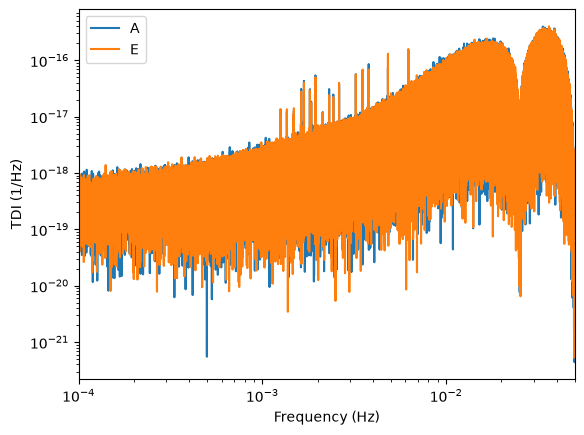

In [7]:
for i in range(len(data_channels_fd)):
    plt.loglog(data_frequency, np.abs(data_channels_fd[i]), label=channel_names[i]) 
plt.xlabel("Frequency (Hz)")
plt.ylabel("TDI (1/Hz)")
plt.legend(loc="upper left")
plt.xlim(1e-4, 0.05)

### select a freuqncy band to be analyzed 

In [8]:
# select a GB to analyze
analyze_gb_idx = 1

true_gb_parameters = {key: inject_parameters[key][analyze_gb_idx] for key in inject_parameters.keys()} 
true_gb_parameters

{'A': 9.402415441563616e-23,
 'f0': 0.0048216991071498,
 'fdot0': 2.53782494976533e-16,
 'inclination': 1.4686945655532282,
 'latitude': 1.1547376242549767,
 'longitude': 3.578406556800828,
 'phase0': 2.680478779022586,
 'psi': 2.4599687248082027}

In [9]:
band_width = 5e-6

band_idx = np.where((data_frequency <= true_gb_parameters["f0"] + band_width/2)&(data_frequency >= true_gb_parameters["f0"] - band_width/2))[0]
data_frequency = data_frequency[band_idx]
data_channels_fd = data_channels_fd[:, band_idx] 

In [10]:
PSDlevel = np.mean(np.median(np.abs(data_channels_fd) ** 2 * 2. / Tobs, axis=1))

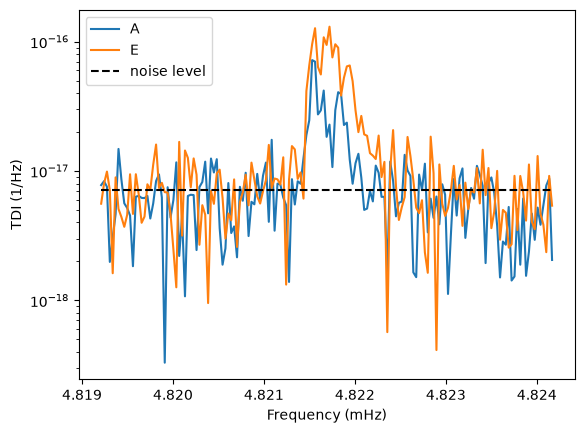

In [11]:
for i in range(len(data_channels_fd)):
    plt.semilogy(data_frequency*1e3, np.abs(data_channels_fd[i]), label=channel_names[i]) 
plt.hlines(np.sqrt(PSDlevel* Tobs / 2.), data_frequency[0]*1e3, data_frequency[-1]*1e3, colors="k", linestyles="--", label="noise level")
plt.xlabel("Frequency (mHz)")
plt.ylabel("TDI (1/Hz)")
plt.legend(loc="upper left")

## Waveform template model 

In [12]:
orbit = Orbit(OrbitDir=ORBIT_DIR)

X2_strings = TDIFly.X2_strings
Y2_strings = TDIStringManipulation.TDIStringCyc(X2_strings)
Z2_strings = TDIStringManipulation.TDIStringCyc(Y2_strings)

gb_tdifly_generator = TDIFlyGB(
    orbit=orbit, 
    Pstring_list=[X2_strings, Y2_strings, Z2_strings], 
    tcb_times=data_time.copy(), 
    Nsparse=512,
    use_gpu=False, 
)

## Likelihood and priors 

### Likelihood wrapper 
$${\rm ln}\mathcal{L}(\boldsymbol{\theta}) = -\frac{1}{2}\langle d - h(\boldsymbol{\theta}) | d - h(\boldsymbol{\theta}) \rangle$$

In [13]:
import bilby 

class bilby_likelihood_wrapper(bilby.Likelihood):
    def __init__(self):
        super().__init__(
            parameters={
                'A': None,
                'f0': None,
                'fdot0': None,
                'inclination': None,
                'latitude': None,
                'longitude': None,
                'phase0': None,
                'psi': None,
            }
        )

    def log_likelihood(self):
        return gb_tdifly_generator.Likelihood(
            data=data_channels_fd, 
            parameters=self.parameters, 
            StartBound=band_idx[0]+1, 
            EndBound=band_idx[-1]+1, 
            Tobs=Tobs, 
            S=PSDlevel, 
        )[0]

/Users/leichang/Documents/Score-Based diffusion in TDC data anysis and parameter estimation/research-repository/environments/triangle-gb/.venv/lib/python3.11/site-packages/bilby/core/likelihood.py:83: FutureWarning: <class '__main__.bilby_likelihood_wrapper'> log_likelihood or log_likelihood_ratio method does not accept 'parameters' as an argument. This is deprecated behaviour  and will be removed in Bilby version 3. See https://bilby-dev.github.io/bilby/parameters for more details.
  warnings.warn(


### Prior 
For the 4 "intrinsic" parameters, we use the same range as example 2. Notice that for some case $\dot{f}_0$ should also include negative values.

In [14]:
priors = bilby.core.prior.PriorDict()
priors["A"] = bilby.prior.LogUniform(minimum=1e-23, maximum=1e-20, name='A', latex_label='$A$')
priors["f0"] = bilby.prior.Uniform(minimum=data_frequency[0], maximum=data_frequency[-1], name="f0", latex_label='$f_0$')
priors["fdot0"] = bilby.prior.Uniform(minimum=0, maximum=TDIFlyGB.fdot_upper_bound(data_frequency[0]), name="fdot0", latex_label='$\dot{f}_0$')
priors["inclination"] = bilby.prior.Sine(minimum=0., maximum=PI, name="inclination", latex_label='$\iota$')
priors["latitude"] = bilby.prior.Cosine(minimum=-PI/2., maximum=PI/2., name="latitude", latex_label='$\\beta$')
priors["longitude"] = bilby.prior.Uniform(minimum=0., maximum=TWOPI, name="longitude", latex_label='$\lambda$', boundary="periodic")
priors["phase0"] = bilby.prior.Uniform(minimum=0., maximum=TWOPI, name="phase0", latex_label='$\\varphi_0$', boundary="periodic")
priors["psi"] = bilby.prior.Uniform(minimum=0., maximum=PI, name="psi", latex_label='$\psi$', boundary="periodic")
priors

{'A': LogUniform(minimum=1e-23, maximum=1e-20, name='A', latex_label='$A$', unit=None, boundary=None),
 'f0': Uniform(minimum=0.004819210879598371, maximum=0.004824167705958519, name='f0', latex_label='$f_0$', unit=None, boundary=None),
 'fdot0': Uniform(minimum=0, maximum=3.193339396586594e-15, name='fdot0', latex_label='$\\dot{f}_0$', unit=None, boundary=None),
 'inclination': Sine(minimum=0.0, maximum=3.141592653589793, name='inclination', latex_label='$\\iota$', unit=None, boundary=None),
 'latitude': Cosine(minimum=-1.5707963267948966, maximum=1.5707963267948966, name='latitude', latex_label='$\\beta$', unit=None, boundary=None),
 'longitude': Uniform(minimum=0.0, maximum=6.283185307179586, name='longitude', latex_label='$\\lambda$', unit=None, boundary='periodic'),
 'phase0': Uniform(minimum=0.0, maximum=6.283185307179586, name='phase0', latex_label='$\\varphi_0$', unit=None, boundary='periodic'),
 'psi': Uniform(minimum=0.0, maximum=3.141592653589793, name='psi', latex_label='$\

## Parameter estimation 

In [15]:
BLike = bilby_likelihood_wrapper()

ncpu = multiprocessing.cpu_count()
print("number of cpus =", ncpu)

result = bilby.run_sampler(
    likelihood=BLike, 
    priors=priors,
    sampler="nessai", 
    # nlive=2000, # seems that nlive=500 is OK
    nlive=500,
    stopping=0.01, 
    npool=ncpu, # use all cpus 
    injection_parameters=true_gb_parameters, 
    outdir="./Samples",
    label="vgb_example",
    plot=True,
    resume=False, 
    # resume=True, 
)

/Users/leichang/Documents/Score-Based diffusion in TDC data anysis and parameter estimation/research-repository/environments/triangle-gb/.venv/lib/python3.11/site-packages/bilby/core/likelihood.py:127: FutureWarning: Setting non-trivial parameters for <class '__main__.bilby_likelihood_wrapper'>. This is deprecated behaviour  and will be removed in Bilby version 3. See https://bilby-dev.github.io/bilby/parameters for more details.
  warnings.warn(msg, FutureWarning)
19:57 bilby INFO    : Running for label 'vgb_example', output will be saved to './Samples'


number of cpus = 10


19:57 bilby INFO    : Analysis priors:


19:57 bilby INFO    : A=LogUniform(minimum=1e-23, maximum=1e-20, name='A', latex_label='$A$', unit=None, boundary=None)


19:57 bilby INFO    : f0=Uniform(minimum=0.004819210879598371, maximum=0.004824167705958519, name='f0', latex_label='$f_0$', unit=None, boundary=None)


...

20:04 bilby INFO    : Finished closing worker pool.


20:04 bilby INFO    : Sampling time: 0:06:40.086822


20:04 bilby WARNING : Result.save_to_file called with extension=True. This will default to json, and ignore the extension from the filename. This behaviour is deprecated and will be removed. 


20:04 bilby WARNING : Result.save_to_file called with extension=True. This will default to json, and ignore the extension from the filename. This behaviour is deprecated and will be removed. 


20:04 bilby INFO    : Summary of results:
nsamples: 2458
ln_noise_evidence:    nan
ln_evidence: -345.512 +/-  0.281
ln_bayes_factor:    nan +/-  0.281



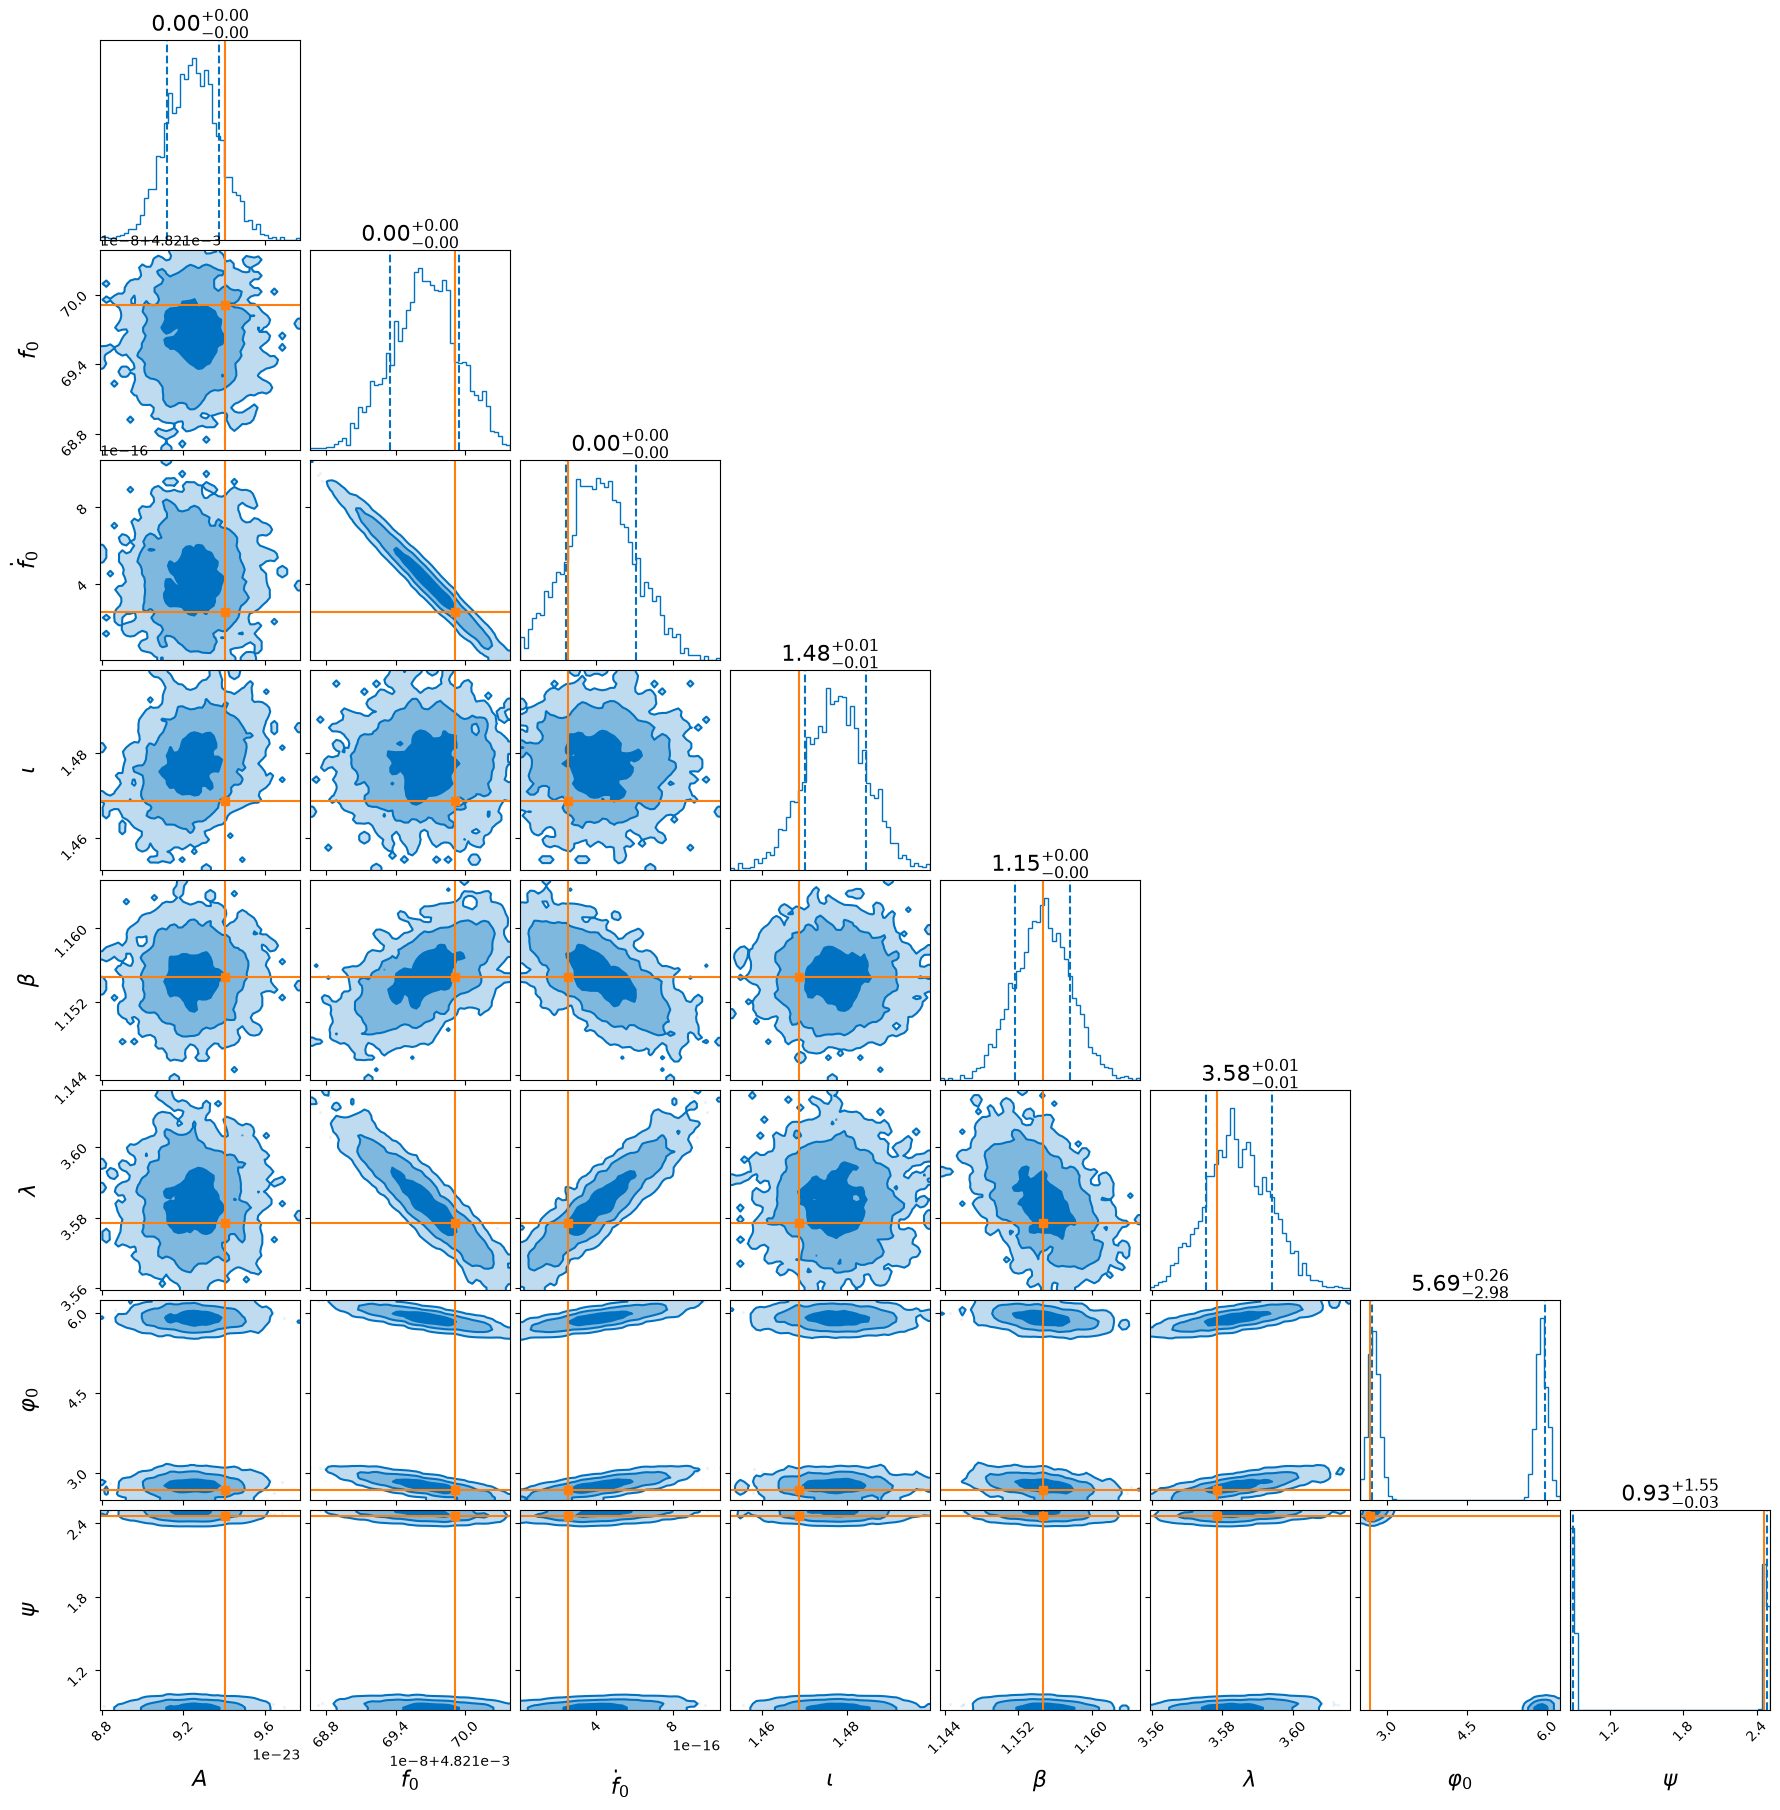

In [16]:
result.plot_corner(save=True)